# Section 8: Clustering Text with Embeddings and a Local LLM

**What you'll learn**
- Turn bank customer messages into embeddings with sentence-transformers
- Measure meaning with cosine similarity and nearest neighbours
- Find intent groups with UMAP and HDBSCAN, with no labels
- Name each group with a local LLM on Ollama
- Run the same pipeline packaged as BERTopic
- Check the found groups against 77 held-back intents

## Setup
- Slides 1-2
- Needs Ollama running, with `ollama pull qwen3.5:4b` done once

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap
import ollama
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import adjusted_rand_score
from bertopic import BERTopic

## Loading Banking77
- Slide 3
- 10,003 messages customers sent to a bank's support chat
- `label_text` is one of 77 intents; it is only used for grading

In [2]:
df = pd.read_json("https://huggingface.co/datasets/mteb/banking77"
                  "/resolve/main/train.jsonl", lines=True)
df.shape

(10003, 3)

In [3]:
df.sample(5)

,text,label,label_text
6612,I have to quickly transfer something to China....,67,transfer_timing
2462,I withdrew $100 but only received $20,75,wrong_amount_of_cash_received
7251,Am I charged a fee to transfer funds?,64,transfer_fee_charged
433,I bought something in another country but the ...,17,card_payment_wrong_exchange_rate
1770,My account is blocked because I entered the wr...,49,pin_blocked


In [4]:
df["label_text"].nunique()

77

## Embedding the Messages
- Slides 4-5
- A small embedding model: 384 numbers per message
- `normalize_embeddings=True` gives every vector length 1, so a dot product is cosine similarity

In [5]:
model = SentenceTransformer("BAAI/bge-small-en-v1.5")
texts = df["text"].tolist()
embeddings = model.encode(texts, normalize_embeddings=True)
embeddings.shape

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

(10003, 384)

## Similar Meaning, Similar Vectors
- Slide 6

In [6]:
examples = ["I lost my card", "Someone stole my card", "How do I top up my account?"]
model.similarity(model.encode(examples), model.encode(examples))

tensor([[1.0000, 0.8823, 0.5571],
        [0.8823, 1.0000, 0.5650],
        [0.5571, 0.5650, 1.0000]])

- The five messages closest to the first one

In [7]:
closest = np.argsort(-(embeddings @ embeddings[0]))[:5]
df.loc[closest, ["text", "label_text"]]

,text,label_text
0,I am still waiting on my card?,card_arrival
61,I am still waiting for my card.,card_arrival
91,I'm still waiting for my card.,card_arrival
45,I'm still waiting for my new card.,card_arrival
39,My card still hasn't been delivered,card_arrival


## k-Means on Embeddings
- Slide 7
- Given the true number of intents, 77

In [8]:
kmeans_labels = KMeans(77).fit_predict(embeddings)
adjusted_rand_score(df["label"], kmeans_labels)

0.5932612744250239

## A Map of the Messages
- Slide 8
- UMAP down to 2 dimensions, coloured by the held-back intent

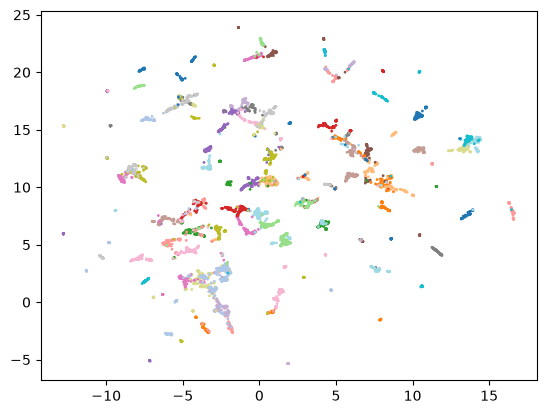

In [9]:
points = umap.UMAP(metric="cosine").fit_transform(embeddings)
plt.scatter(points[:, 0], points[:, 1], c=df["label"], s=1, cmap="tab20")
plt.show()

## UMAP, Then HDBSCAN
- Slide 9
- UMAP to 5 dimensions keeps more structure than 2, and HDBSCAN copes far better than in 384
- HDBSCAN chooses the number of groups; a group needs at least 40 messages

In [10]:
reduced = umap.UMAP(n_components=5, metric="cosine").fit_transform(embeddings)
df["cluster"] = HDBSCAN(min_cluster_size=40, copy=True).fit_predict(reduced)
df["cluster"].max() + 1, (df["cluster"] == -1).mean()

(np.int64(73), np.float64(0.15595321403578927))

In [11]:
adjusted_rand_score(df["label"], df["cluster"])

0.3347509226113807

## Reading One Cluster
- Slide 10

In [12]:
df[df["cluster"] == 0]["text"].head(10).tolist()

['I am interested in changing my personal details.',
 'I am here to change my adress.',
 "I'd like to make some changes to my personal information.",
 'I would like to change my name after marriage.',
 'I would like to change my adress',
 'My address is incorrect on my file.',
 'My address details have changed and I want to update them',
 'Where do I go to edit my personal details on my account?',
 'I need to change my name, since i just got married',
 'I moved to a new city and need to change my address']

In [13]:
df[df["cluster"] == 0]["label_text"].value_counts().head(3)

label_text
edit_personal_details    120
verify_my_identity         1
Name: count, dtype: int64

- A few messages the clustering called noise

In [14]:
df[df["cluster"] == -1]["text"].head(5).tolist()

['How do I know if I will get my card, or if it is lost?',
 'Do you have info about the card on delivery?',
 'Have you sent out my card yet?',
 'Can I get an update on my replacement card?',
 'I need to find out where the card is that I ordered.']

## Naming a Cluster With a Local LLM
- Slide 11
- Ten messages from the cluster go into one prompt
- `think=False` asks for the answer only, with no reasoning text

In [15]:
prompt = ("Give a short name (2 to 5 words) for the customer intent shared by these "
          "bank messages. "
          "Reply with the name only.\n\n")
messages = "\n".join(df[df["cluster"] == 0]["text"].head(10))
response = ollama.chat(model="qwen3.5:4b",
                       messages=[{"role": "user", "content": prompt + messages}],
                       think=False)
response.message.content

'Change Personal Details'

- The same for the first ten clusters, next to the most common true intent

In [16]:
for c in range(10):
    messages = "\n".join(df[df["cluster"] == c]["text"].head(10))
    response = ollama.chat(model="qwen3.5:4b",
                           messages=[{"role": "user", "content": prompt + messages}],
                           think=False)
    print(c, response.message.content, "|",
          df[df["cluster"] == c]["label_text"].mode()[0])

0 Update personal details | edit_personal_details
1 Delete bank account | terminate_account


2 Find source of funds | verify_source_of_funds
3 Change Card PIN Number | change_pin


4 Card ATM locations | atm_support
5 Minimum age requirements | age_limit


6 Virtual card limits inquiry | get_disposable_virtual_card
7 Verify Top-Up Card Method | verify_top_up


8 Disposable Card Limits and Features | disposable_card_limits
9 Order Virtual Card | getting_virtual_card


## BERTopic: the Same Pipeline, Packaged
- Slide 12
- Embeddings, UMAP, HDBSCAN, then keywords per topic
- Pass the embeddings already computed so nothing is encoded twice

In [17]:
topic_model = BERTopic(embedding_model=model, min_topic_size=40)
topics, _ = topic_model.fit_transform(texts, embeddings)
topic_model.get_topic_info()[["Topic", "Count", "Name"]].head(10)

,Topic,Count,Name
0,-1,1252,-1_the_exchange_it_to
1,0,382,0_fee_extra_charged_statement
2,1,330,1_identity_verify_verification_id
3,2,304,2_currencies_currency_salary_fiat
4,3,244,3_balance_deposited_deposit_cheque
5,4,205,4_charged_fee_cash_atm
6,5,202,5_transfer_failed_tried_error
7,6,198,6_cancel_transaction_made_rent
8,7,194,7_fee_charged_transfer_transfers
9,8,176,8_topping_top_up_by


In [18]:
adjusted_rand_score(df["label"], topics)

0.4012935732940459

- The keywords behind one topic

In [19]:
topic_model.get_topic(0)

[('fee', np.float64(0.057512770081138656)),
 ('extra', np.float64(0.05741541479587916)),
 ('charged', np.float64(0.044744574208384735)),
 ('statement', np.float64(0.0360008245017528)),
 ('charge', np.float64(0.03209232218681569)),
 ('pound', np.float64(0.02877213418893294)),
 ('an', np.float64(0.02669113254626985)),
 ('why', np.float64(0.024854380935126246)),
 ('fees', np.float64(0.02389061621051943)),
 ('on', np.float64(0.022179426264275073))]

## Comparing the Groupings
- Slide 13

In [20]:
pd.Series({
    "k-means, told 77": adjusted_rand_score(df["label"], kmeans_labels),
    "UMAP + HDBSCAN": adjusted_rand_score(df["label"], df["cluster"]),
    "BERTopic": adjusted_rand_score(df["label"], topics),
})

k-means, told 77    0.593261
UMAP + HDBSCAN      0.334751
BERTopic            0.401294
dtype: float64

## Lab: Sorting New Messages
- Send new messages to the closest BERTopic topic
- Write a few of your own and see where they land

In [21]:
new = ["My card hasn't arrived yet", "Why was I charged a fee for withdrawing cash?",
       "I want to close my account"]
new_topics, _ = topic_model.transform(new)
topic_model.get_topic_info().set_index("Topic").loc[new_topics, "Name"]

Topic
13            13_new_arrive_card_here
4              4_charged_fee_cash_atm
30    30_delete_close_account_service
Name: Name, dtype: str

## Wrap-Up
- Slides 14-17